# 06 · Unsupervised Learning — Clustering & Dimensionality Reduction

No labels this time — only **X**. The goal is to discover structure:
- **Clustering:** which samples belong together? (customer segments, grouping documents)
- **Dimensionality reduction:** can we describe 64 features with 2 without losing much? (visualisation, compression, denoising, faster models)

**What you'll learn**
1. **K-Means** 🐍 pure Python → 🔢 NumPy → 📦 scikit-learn, plus K-Means++ and choosing k (elbow, silhouette)
2. When K-Means fails, and **DBSCAN**, **hierarchical clustering** and **Gaussian Mixture Models** as alternatives
3. **PCA** — the geometry, three ways to compute it, and how many components to keep
4. **t-SNE** for visualisation, and a quick look at anomaly detection

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math, random
plt.rcParams["figure.figsize"] = (5.5, 3.6)
plt.rcParams["axes.grid"] = True; plt.rcParams["grid.alpha"] = 0.3
rng = np.random.default_rng(0)

---
# Part A — Clustering

## A1. K-Means intuition
You choose **k**, the number of clusters. Each cluster has a centre (**centroid**). Then alternate two steps until nothing changes:
1. **Assign:** each point joins its nearest centroid.
2. **Update:** move each centroid to the mean of its points.

It minimises the **inertia** (within-cluster sum of squares): $\sum_i \|\mathbf{x}_i - \boldsymbol{\mu}_{c(i)}\|^2$. Each step can only lower it, so it always converges — but possibly to a *local* minimum, depending on the starting centroids.

In [2]:
# 🐍 Pure Python K-Means
def kmeans_python(X, k, iters=100, seed=0):
    rnd = random.Random(seed)
    centroids = [list(p) for p in rnd.sample(X, k)]          # start: k random data points
    for it in range(iters):
        # 1. assign
        clusters = [[] for _ in range(k)]
        labels = []
        for p in X:
            dists = [sum((pi - ci) ** 2 for pi, ci in zip(p, c)) for c in centroids]
            j = dists.index(min(dists))
            clusters[j].append(p); labels.append(j)
        # 2. update
        new = [[sum(col) / len(cl) for col in zip(*cl)] if cl else centroids[j] for j, cl in enumerate(clusters)]
        if new == centroids:
            break
        centroids = new
    return centroids, labels, it + 1

from sklearn.datasets import make_blobs
Xb, yb_true = make_blobs(300, centers=4, cluster_std=0.9, random_state=2)
cents, labels, n_it = kmeans_python(Xb.tolist(), k=4)
print(f"converged in {n_it} iterations; centroids:", np.round(cents, 2).tolist())

converged in 4 iterations; centroids: [[-1.36, -3.56], [0.8, -1.29], [-1.35, -9.45], [-6.03, 2.14]]


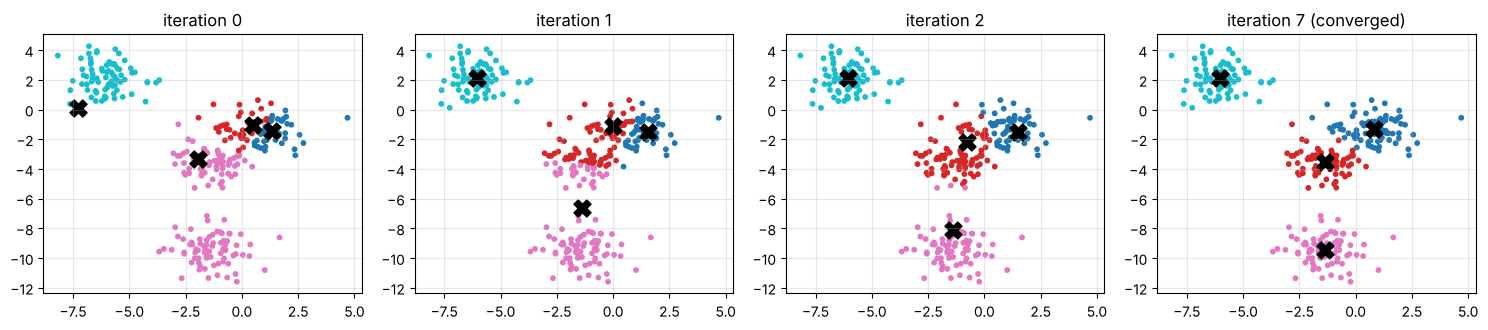

In [3]:
# 🔢 NumPy K-Means with K-Means++ initialisation, recording every step for plotting
def kmeans_pp_init(X, k, rng):
    """K-Means++: pick the first centre at random, then each next centre with probability ∝ distance² to
    the nearest existing centre — spreads the starting centres out and avoids bad local minima."""
    C = [X[rng.integers(len(X))]]
    for _ in range(k - 1):
        d2 = np.min(((X[:, None, :] - np.array(C)) ** 2).sum(-1), axis=1)
        C.append(X[rng.choice(len(X), p=d2 / d2.sum())])
    return np.array(C)

class KMeansNP:
    def __init__(self, k, iters=100, init="k-means++", seed=0):
        self.k, self.iters, self.init, self.seed = k, iters, init, seed
    def fit(self, X):
        rng = np.random.default_rng(self.seed)
        C = kmeans_pp_init(X, self.k, rng) if self.init == "k-means++" else X[rng.choice(len(X), self.k, replace=False)]
        self.history = [C.copy()]
        for _ in range(self.iters):
            d2 = ((X[:, None, :] - C[None, :, :]) ** 2).sum(-1)       # (n, k) squared distances
            labels = d2.argmin(1)                                      # 1. assign
            newC = np.array([X[labels == j].mean(0) if np.any(labels == j) else C[j] for j in range(self.k)])  # 2. update
            self.history.append(newC.copy())
            if np.allclose(newC, C):
                break
            C = newC
        self.centroids, self.labels_ = C, labels
        self.inertia_ = d2[np.arange(len(X)), labels].sum()
        return self
    def predict(self, X):
        return ((X[:, None, :] - self.centroids[None]) ** 2).sum(-1).argmin(1)

km = KMeansNP(4, init="random", seed=3).fit(Xb)
steps = [0, 1, 2, len(km.history) - 1]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, s in zip(axes, steps):
    C = km.history[s]; lab = ((Xb[:, None] - C[None]) ** 2).sum(-1).argmin(1)
    ax.scatter(Xb[:, 0], Xb[:, 1], c=lab, s=10, cmap="tab10"); ax.scatter(C[:, 0], C[:, 1], c="k", marker="X", s=150)
    ax.set_title(f"iteration {s}" + (" (converged)" if s == steps[-1] else ""))
plt.tight_layout(); plt.show()

In [4]:
# 📦 scikit-learn
from sklearn.cluster import KMeans
sk = KMeans(4, n_init=10, random_state=0).fit(Xb)
print(f"our inertia: {KMeansNP(4).fit(Xb).inertia_:.1f}   sklearn inertia: {sk.inertia_:.1f}")
print("sklearn runs K-Means n_init=10 times from different starts and keeps the best — a standard trick.")

our inertia: 493.8   sklearn inertia: 493.8
sklearn runs K-Means n_init=10 times from different starts and keeps the best — a standard trick.


## A2. Choosing k
- **Elbow method:** plot inertia vs k. Inertia always falls as k grows; look for the "elbow" where it stops falling fast.
- **Silhouette score:** for each point, $s = \frac{b - a}{\max(a, b)}$ where *a* = mean distance to its own cluster and *b* = mean distance to the nearest other cluster. Ranges from −1 to 1; higher = better-separated clusters. Pick the k with the highest average.

silhouette for k=4 — by hand: 0.6337   sklearn: 0.6337


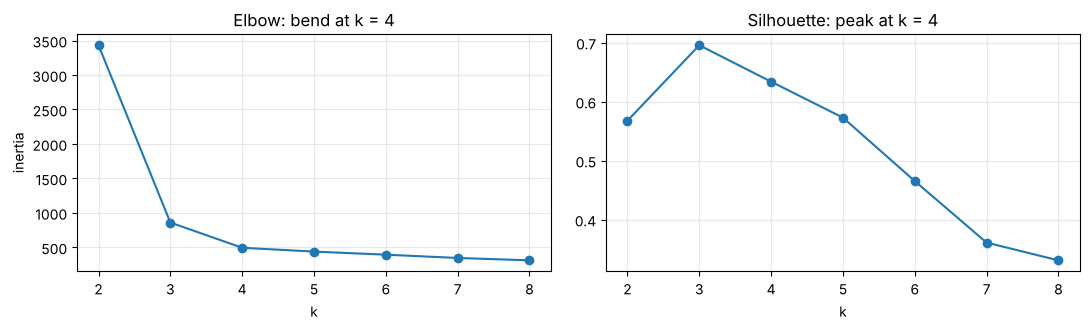

In [5]:
# 🐍 silhouette by hand (O(n²) — fine for a few hundred points)
def silhouette_python(X, labels):
    n = len(X); dist = lambda a, b: math.sqrt(sum((x - y) ** 2 for x, y in zip(a, b)))
    total = 0.0
    for i in range(n):
        same = [dist(X[i], X[j]) for j in range(n) if labels[j] == labels[i] and j != i]
        if not same:
            continue
        a = sum(same) / len(same)
        b = min(sum(dist(X[i], X[j]) for j in range(n) if labels[j] == c) / labels.count(c)
                for c in set(labels) if c != labels[i])
        total += (b - a) / max(a, b)
    return total / n

from sklearn.metrics import silhouette_score
ks = range(2, 9)
inertias, sils = [], []
for k in ks:
    m = KMeans(k, n_init=10, random_state=0).fit(Xb)
    inertias.append(m.inertia_); sils.append(silhouette_score(Xb, m.labels_))
print(f"silhouette for k=4 — by hand: {silhouette_python(Xb.tolist(), KMeans(4, n_init=10, random_state=0).fit(Xb).labels_.tolist()):.4f}   sklearn: {sils[2]:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(ks, inertias, "o-"); ax[0].set_title("Elbow: bend at k = 4"); ax[0].set_xlabel("k"); ax[0].set_ylabel("inertia")
ax[1].plot(ks, sils, "o-"); ax[1].set_title("Silhouette: peak at k = 4"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()

## A3. Where K-Means fails

K-Means assumes clusters are **round blobs of similar size** (it splits space into straight-edged regions around centroids). It fails on elongated, nested or curved shapes, and is sensitive to outliers and feature scaling.

### DBSCAN — clusters as dense regions
- A point with at least `min_samples` neighbours within distance `eps` is a **core point**.
- Clusters grow by linking core points that are within `eps` of each other.
- Points not reachable from any core point are **noise** (label −1).

✅ finds any shape, finds k itself, flags outliers. ❌ struggles when clusters have very different densities; `eps` needs tuning.

### Hierarchical (agglomerative) clustering
Start with every point as its own cluster and repeatedly **merge the two closest clusters**. The full merge history is a tree — a **dendrogram** — and you cut it at any height to get any number of clusters. "Closest" is defined by the **linkage**: *single* (closest pair — follows chains/curves), *complete* (farthest pair), *average*, or *Ward* (smallest increase in variance — K-Means-like).

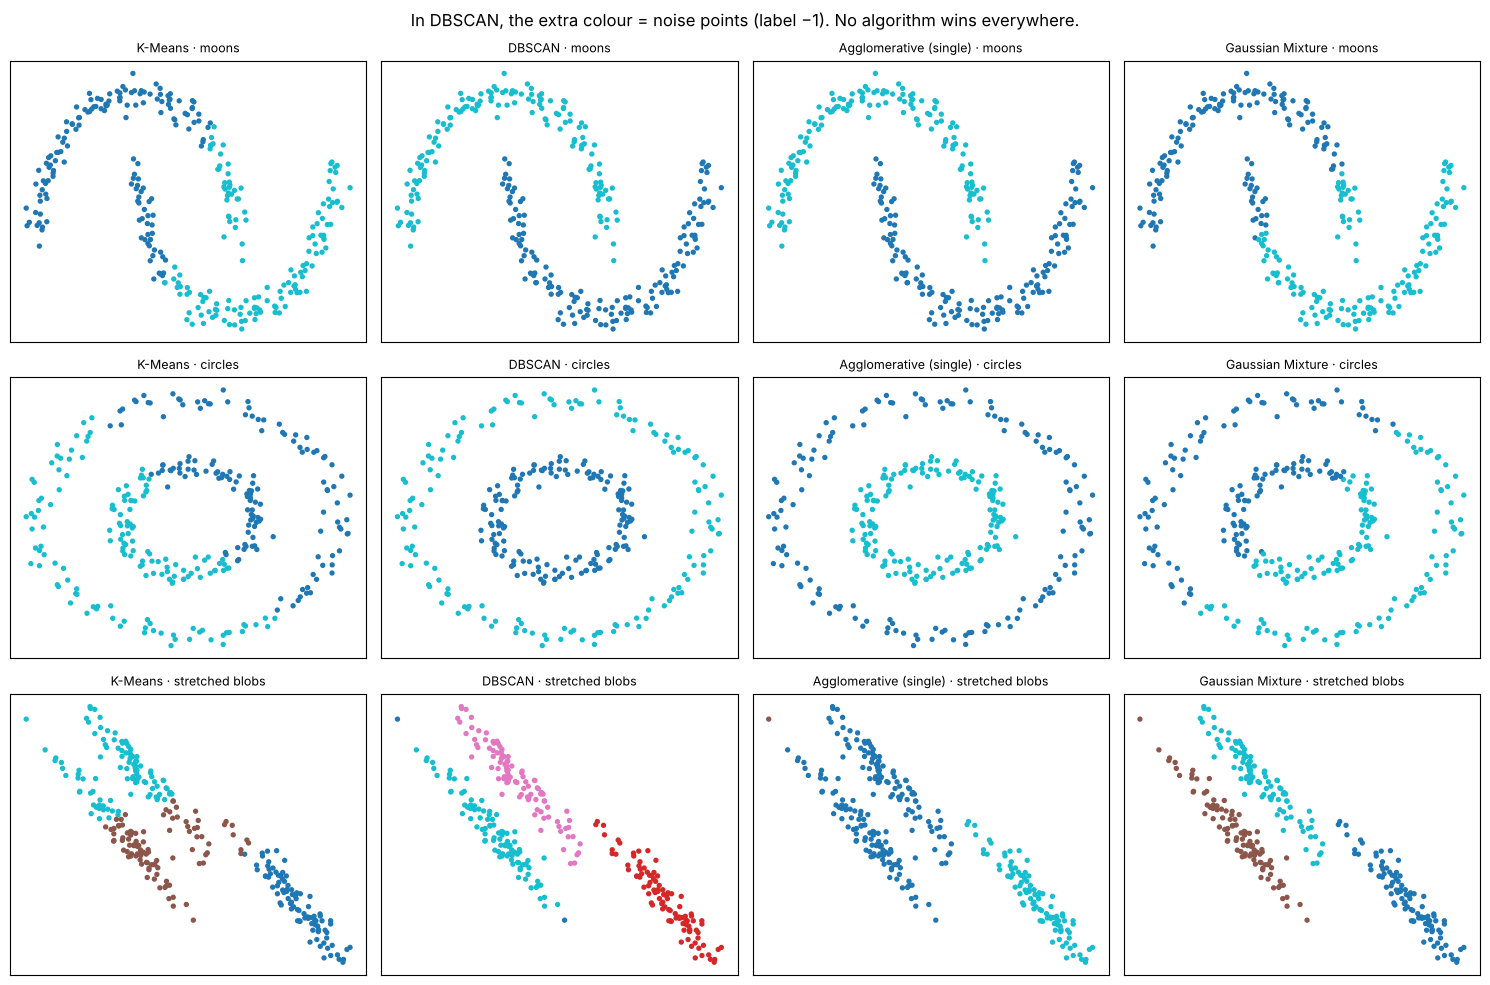

In [6]:
from sklearn.datasets import make_moons, make_circles
from sklearn.cluster import DBSCAN, AgglomerativeClustering
from sklearn.mixture import GaussianMixture

datasets = {"moons": make_moons(300, noise=0.06, random_state=0)[0],
            "circles": make_circles(300, factor=0.45, noise=0.05, random_state=0)[0],
            "stretched blobs": make_blobs(300, centers=3, random_state=170)[0] @ np.array([[0.6, -0.64], [-0.41, 0.85]])}
n_clusters = {"moons": 2, "circles": 2, "stretched blobs": 3}
eps = {"moons": 0.2, "circles": 0.2, "stretched blobs": 0.5}

def run_all(X, k, e):
    return {"K-Means": KMeans(k, n_init=10, random_state=0).fit_predict(X),
            "DBSCAN": DBSCAN(eps=e, min_samples=5).fit_predict(X),
            "Agglomerative (single)": AgglomerativeClustering(k, linkage="single").fit_predict(X),
            "Gaussian Mixture": GaussianMixture(k, covariance_type="full", random_state=0).fit_predict(X)}

fig, axes = plt.subplots(3, 4, figsize=(15, 10))
for i, (dname, X) in enumerate(datasets.items()):
    for j, (aname, lab) in enumerate(run_all(X, n_clusters[dname], eps[dname]).items()):
        axes[i, j].scatter(X[:, 0], X[:, 1], c=lab, cmap="tab10", s=8)
        axes[i, j].set_title(f"{aname} · {dname}", fontsize=9); axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
plt.suptitle("In DBSCAN, the extra colour = noise points (label −1). No algorithm wins everywhere.")
plt.tight_layout(); plt.show()

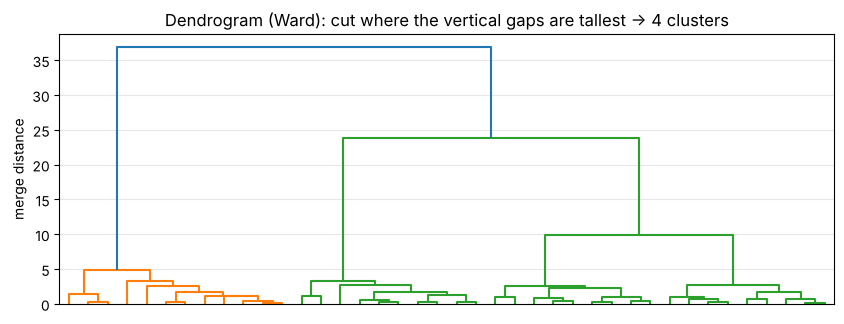

In [7]:
# A dendrogram (scipy is installed with scikit-learn)
from scipy.cluster.hierarchy import linkage, dendrogram
Z = linkage(Xb[:40], method="ward")
plt.figure(figsize=(10, 3.5)); dendrogram(Z, no_labels=True)
plt.title("Dendrogram (Ward): cut where the vertical gaps are tallest → 4 clusters"); plt.ylabel("merge distance"); plt.show()

### Gaussian Mixture Models — soft, elliptical clusters
A GMM says the data came from k Gaussian (bell-shaped) blobs, each with its own mean, **covariance** (shape & orientation) and weight. It's fit with the **EM algorithm**, which looks just like K-Means:
- **E-step:** compute each point's *probability* of belonging to each blob (soft assignment, instead of K-Means' hard one).
- **M-step:** re-estimate each blob's mean, covariance and weight from those probabilities.

K-Means is a special case: equal round blobs with hard assignments. GMMs also give a density, so low-probability points are natural **anomalies**.

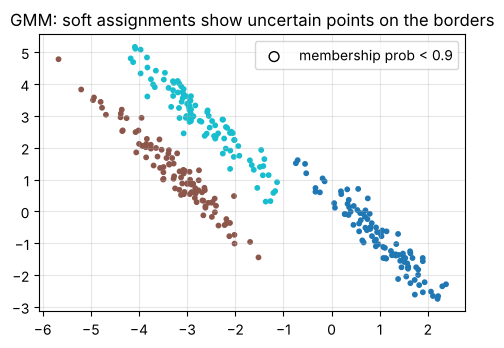

In [8]:
X3 = datasets["stretched blobs"]
gmm = GaussianMixture(3, random_state=0).fit(X3)
probs = gmm.predict_proba(X3)
uncertain = probs.max(1) < 0.9
plt.scatter(X3[:, 0], X3[:, 1], c=probs.argmax(1), cmap="tab10", s=10)
plt.scatter(X3[uncertain, 0], X3[uncertain, 1], facecolors="none", edgecolors="k", s=50, label="membership prob < 0.9")
plt.legend(); plt.title("GMM: soft assignments show uncertain points on the borders"); plt.show()

---
# Part B — Dimensionality Reduction with PCA

## B1. Intuition
Imagine photographing a 3-D object. The best camera angle is the one showing the **most spread** — you can tell most about the object from it. PCA finds those angles for data:

- **1st principal component (PC1):** the direction along which the data varies the **most**.
- **PC2:** the direction of most remaining variance, **perpendicular** to PC1. And so on.

Projecting onto the first few PCs keeps most of the information (variance) in far fewer numbers. Mathematically, the PCs are the **eigenvectors of the covariance matrix**, and each eigenvalue is the variance along its PC.

Steps:
1. **Centre** the data (subtract each feature's mean). Usually also **standardise** if features have different units.
2. Covariance matrix $C = \frac{1}{n-1} X^\top X$.
3. Eigen-decompose $C$; sort by eigenvalue, largest first.
4. Project: $Z = X W_k$ where $W_k$ holds the top-k eigenvectors as columns.

variance along each PC: [4.8   0.238]  → explained ratio: [0.953 0.047]


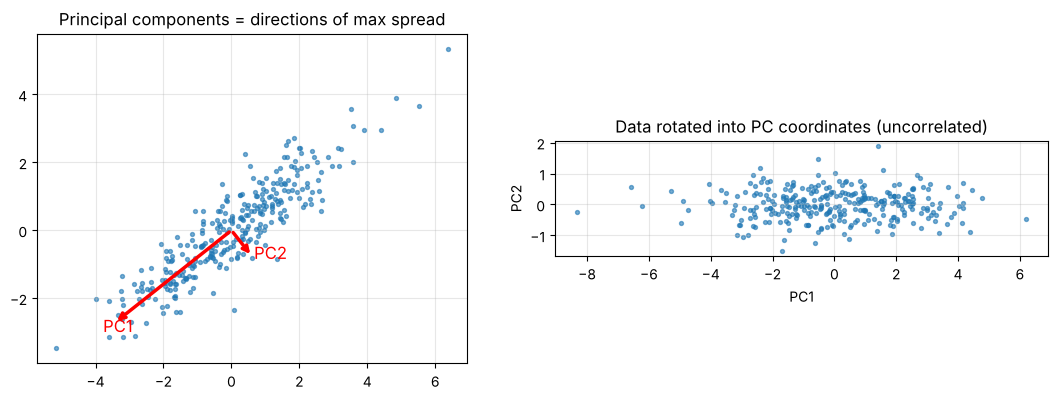

In [9]:
# Correlated 2-D data
X2 = rng.multivariate_normal([0, 0], [[3, 2.2], [2.2, 2]], 300)

# 🔢 NumPy PCA via eigendecomposition of the covariance matrix
Xc = X2 - X2.mean(0)
C = Xc.T @ Xc / (len(Xc) - 1)
eigvals, eigvecs = np.linalg.eigh(C)              # eigh: for symmetric matrices, returns ascending order
order = np.argsort(eigvals)[::-1]; eigvals, eigvecs = eigvals[order], eigvecs[:, order]
print("variance along each PC:", eigvals.round(3), " → explained ratio:", (eigvals / eigvals.sum()).round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(Xc[:, 0], Xc[:, 1], s=8, alpha=0.6)
for v, s, name in zip(eigvecs.T, np.sqrt(eigvals), ["PC1", "PC2"]):
    ax[0].annotate("", xy=v * s * 2, xytext=(0, 0), arrowprops=dict(arrowstyle="->", lw=2.5, color="r"))
    ax[0].text(*(v * s * 2.2), name, color="r", fontsize=12)
ax[0].set_aspect("equal"); ax[0].set_title("Principal components = directions of max spread")
Z = Xc @ eigvecs
ax[1].scatter(Z[:, 0], Z[:, 1], s=8, alpha=0.6); ax[1].set_aspect("equal")
ax[1].set_title("Data rotated into PC coordinates (uncorrelated)"); ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2")
plt.tight_layout(); plt.show()

In [10]:
# 🐍 Pure Python: PC1 by POWER ITERATION — multiply a random vector by C again and again;
# it swings toward the eigenvector with the largest eigenvalue.
def power_iteration_python(C, iters=200):
    v = [1.0] * len(C)
    for _ in range(iters):
        w = [sum(C[i][j] * v[j] for j in range(len(v))) for i in range(len(v))]   # w = C v
        norm = math.sqrt(sum(x * x for x in w))
        v = [x / norm for x in w]                                                   # normalise
    eigval = sum(v[i] * sum(C[i][j] * v[j] for j in range(len(v))) for i in range(len(v)))  # vᵀCv
    return v, eigval

v1, l1 = power_iteration_python(C.tolist())
print("pure Python PC1:", np.round(v1, 4), " variance:", round(l1, 4))
print("NumPy PC1:      ", eigvecs[:, 0].round(4), " (sign may flip — both directions describe the same line)")

pure Python PC1: [0.7839 0.6209]  variance: 4.7999
NumPy PC1:       [-0.7839 -0.6209]  (sign may flip — both directions describe the same line)


In [11]:
# 🔢 PCA via SVD — what libraries actually do (more numerically stable; never forms XᵀX)
U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
print("SVD PC1:", Vt[0].round(4), "  variance = S²/(n−1):", (S ** 2 / (len(Xc) - 1)).round(3))

# 📦 scikit-learn
from sklearn.decomposition import PCA
pca = PCA().fit(X2)
print("sklearn PC1:", pca.components_[0].round(4), "  explained_variance_:", pca.explained_variance_.round(3))

SVD PC1: [0.7839 0.6209]   variance = S²/(n−1): [4.8   0.238]
sklearn PC1: [0.7839 0.6209]   explained_variance_: [4.8   0.238]


## B2. A real example: handwritten digits (64 features → 2)

Each digit is an 8×8 image = 64 pixel features. PCA can squash them to 2 numbers for a plot, and tells us how many components we need to keep, say, 90% of the variance.

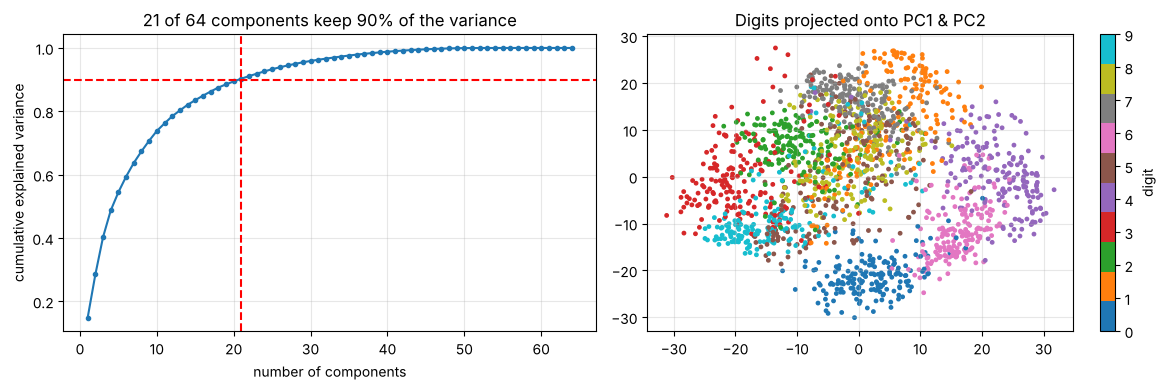

In [12]:
from sklearn.datasets import load_digits
digits = load_digits(); Xd, yd = digits.data, digits.target

pca_d = PCA().fit(Xd)
cum = np.cumsum(pca_d.explained_variance_ratio_)
k90 = np.argmax(cum >= 0.9) + 1
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(1, 65), cum, "o-", ms=3); ax[0].axhline(0.9, ls="--", c="r"); ax[0].axvline(k90, ls="--", c="r")
ax[0].set_xlabel("number of components"); ax[0].set_ylabel("cumulative explained variance")
ax[0].set_title(f"{k90} of 64 components keep 90% of the variance")
Z2 = PCA(2).fit_transform(Xd)
sc = ax[1].scatter(Z2[:, 0], Z2[:, 1], c=yd, cmap="tab10", s=6); plt.colorbar(sc, ax=ax[1], label="digit")
ax[1].set_title("Digits projected onto PC1 & PC2"); plt.tight_layout(); plt.show()

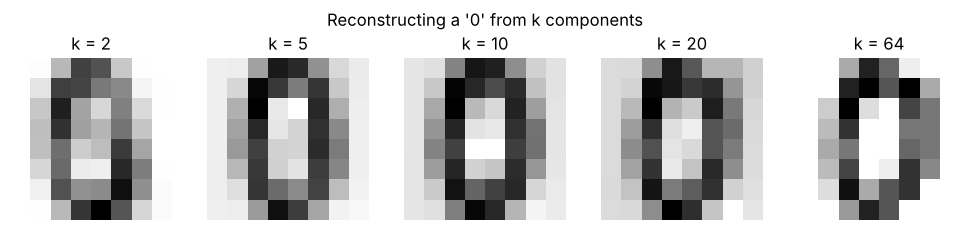

In [13]:
# Reconstruction: compress to k numbers and decompress back to 64 pixels
fig, axes = plt.subplots(1, 5, figsize=(10, 2.3))
for ax, k in zip(axes, [2, 5, 10, 20, 64]):
    p = PCA(k).fit(Xd)
    rec = p.inverse_transform(p.transform(Xd[:1]))
    ax.imshow(rec.reshape(8, 8), cmap="gray_r"); ax.set_title(f"k = {k}"); ax.axis("off")
plt.suptitle(f"Reconstructing a '{yd[0]}' from k components"); plt.tight_layout(); plt.show()

## B3. t-SNE — for pictures, not features

PCA is **linear**: it can only rotate and flatten. **t-SNE** (and the similar **UMAP**) is **non-linear**: it places points in 2-D so that points that were *neighbours* in high-dimensional space stay neighbours. It usually gives much clearer cluster pictures.

⚠️ Use t-SNE only for **visualisation**: distances *between* clusters and cluster *sizes* in the plot are not meaningful, the result depends on the `perplexity` setting and random seed, and it can't embed new points.

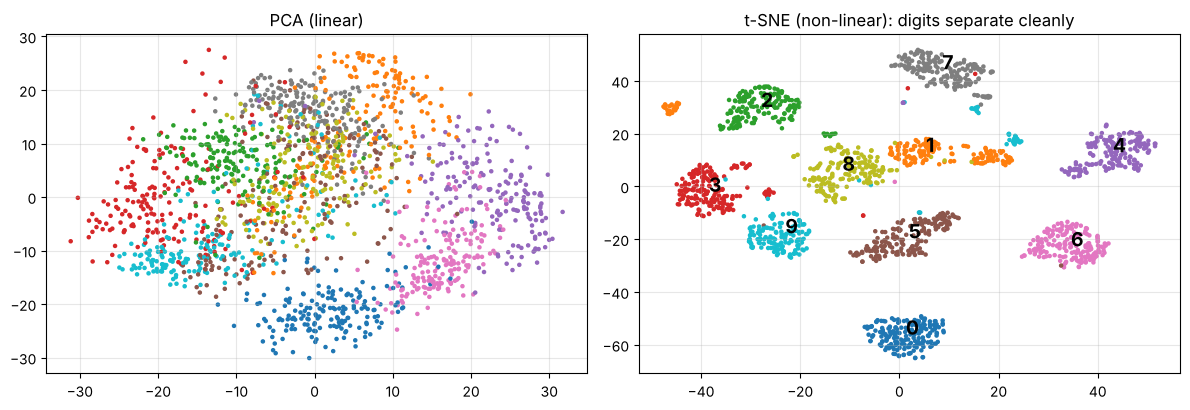

In [14]:
from sklearn.manifold import TSNE
Zt = TSNE(2, perplexity=30, random_state=0, init="pca").fit_transform(Xd)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].scatter(Z2[:, 0], Z2[:, 1], c=yd, cmap="tab10", s=5); ax[0].set_title("PCA (linear)")
ax[1].scatter(Zt[:, 0], Zt[:, 1], c=yd, cmap="tab10", s=5); ax[1].set_title("t-SNE (non-linear): digits separate cleanly")
for d in range(10):
    ax[1].text(*np.median(Zt[yd == d], 0), str(d), fontsize=14, weight="bold")
plt.tight_layout(); plt.show()

## B4. Bonus — anomaly detection

Unsupervised methods are a natural fit for finding the odd ones out (fraud, defects, intrusions), since anomalies are rare and often unlabelled:
- **Distance / density:** points far from any cluster, or in low-density regions (DBSCAN noise, low GMM likelihood).
- **Isolation Forest:** random trees isolate anomalies in **fewer splits** because they're few and different.
- **Reconstruction error:** PCA (or an autoencoder) reconstructs normal points well and anomalies badly.

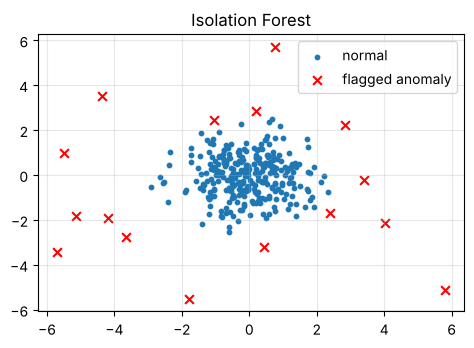

In [15]:
from sklearn.ensemble import IsolationForest
normal = rng.normal(0, 1, (300, 2)); outliers = rng.uniform(-6, 6, (15, 2))
Xa = np.vstack([normal, outliers])
flag = IsolationForest(contamination=0.05, random_state=0).fit_predict(Xa)   # −1 = anomaly
plt.scatter(*Xa[flag == 1].T, s=10, label="normal"); plt.scatter(*Xa[flag == -1].T, s=40, c="r", marker="x", label="flagged anomaly")
plt.legend(); plt.title("Isolation Forest"); plt.show()

## Key takeaways
- **K-Means:** assign → update until stable; use K-Means++ init and several restarts; pick k with elbow/silhouette; assumes round, similar-size clusters; **scale features first**.
- **DBSCAN** for arbitrary shapes + noise; **hierarchical** for a full tree of clusterings; **GMM** for soft, elliptical clusters.
- **PCA** = eigenvectors of the covariance matrix (computed via SVD); keep enough components for ~90–95% variance; it's linear.
- **t-SNE/UMAP** for visualisation only.

## Exercises
1. Run `KMeansNP` with `init="random"` for seeds 0–19 on `Xb`. How often does it get stuck in a worse local minimum than K-Means++?
2. Use PCA to reduce the digits to 10, 20 and 30 components, then train a logistic regression on each. How does accuracy compare with all 64?
3. Implement the GMM **E-step** in NumPy: given means, covariances and weights, compute each point's responsibility using `scipy.stats.multivariate_normal`.

In [16]:
# Exercise 1 — solution
rand = [KMeansNP(4, init="random", seed=s).fit(Xb).inertia_ for s in range(20)]
pp = [KMeansNP(4, init="k-means++", seed=s).fit(Xb).inertia_ for s in range(20)]
best = min(rand + pp)
print(f"random init stuck in a worse minimum: {sum(r > best * 1.01 for r in rand)}/20 runs")
print(f"k-means++ stuck in a worse minimum:   {sum(r > best * 1.01 for r in pp)}/20 runs")

random init stuck in a worse minimum: 8/20 runs
k-means++ stuck in a worse minimum:   5/20 runs


In [17]:
# Exercise 2 — solution
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
for k in [10, 20, 30, 64]:
    s = cross_val_score(make_pipeline(StandardScaler(), PCA(k), LogisticRegression(max_iter=3000)), Xd, yd, cv=5).mean()
    print(f"{k:2d} components → accuracy {s:.3f}")

10 components → accuracy 0.840
20 components → accuracy 0.899


30 components → accuracy 0.907
64 components → accuracy 0.920


**Next:** [07 · Neural Networks](07_neural_networks.ipynb) — stacking logistic regressions into a network that can learn almost anything.

*Going deeper / interview prep:* `ML_Interview_Notes.md` (unsupervised section) · `Linear_Algebra_Notes.md` Parts 7 & 9 (eigenvectors, SVD, PCA via SVD, power iteration) · code: `ml_from_scratch.py` → `KMeans`, `DBSCAN`, `AgglomerativeClustering`, `PCA`, `GaussianMixture` · `ml_from_scratch_part2.py` → `TSNE`, `SpectralClustering`, `IsolationForest`, `MeanShift`.